<a href="https://colab.research.google.com/github/miyagi-art/simulacion2/blob/main/M%C3%A9todo_de_Euler_Maruyama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tiempo     Euler-Maruyama     Solucion exacta
 0.00          1.00000            1.00000
 0.20          1.11937            1.11669
 0.40          1.32726            1.33255
 0.60          1.15529            1.16012
 0.80          1.12625            1.12118
 1.00          1.16147            1.14644
 1.20          1.39871            1.39364
 1.40          1.51795            1.50405
 1.60          1.52368            1.49622
 1.80          1.65714            1.61855
 2.00          1.99722            1.96945
 2.20          2.51167            2.52524
 2.40          1.64528            1.77250
 2.60          1.29350            1.41847
 2.80          1.29779            1.41043
 3.00          1.16194            1.25887
 3.20          1.03504            1.11852
 3.40          1.13832            1.22481
 3.60          0.70373            0.82862
 3.80          0.60874            0.71750
 4.00          0.45314            0.55068
 4.20          0.41452            0.50117
 4.40          0.40366        

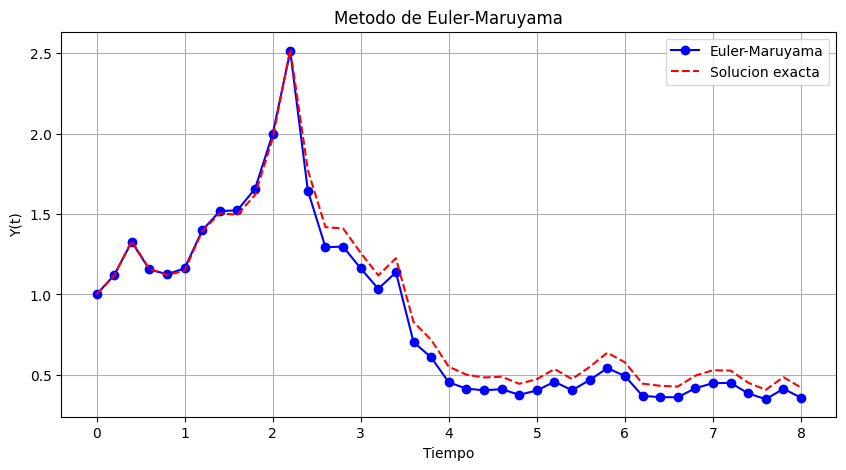

In [4]:


import numpy as np
import matplotlib.pyplot as plt

# Parametros
r = 0.1
sigma = 0.3
dt = 0.2
a = 0
b = 8

# Condicion inicial
y0 = 1  # y(0) = 1

# Numero de iteraciones
n = int((b - a) / dt)

# Vectores
t = np.linspace(a, b, n + 1)
W = np.zeros(n + 1)
B = np.zeros(n + 1)

# Valor inicial
W[0] = 1

# Metodo de Euler-Maruyama
for i in range(n):

    Z = np.random.normal(0, 1)

    delta_B = Z * np.sqrt(dt)

    B[i + 1] = B[i] + delta_B

    W[i + 1] = W[i] + r * W[i] * dt + sigma * W[i] * delta_B

# Solucion exacta
Y = y0 * np.exp((r - 0.5 * sigma**2) * t + sigma * B)

# Mostrar resultados
print("Tiempo     Euler-Maruyama     Solucion exacta")

for i in range(n + 1):
    print(f"{t[i]:5.2f}       {W[i]:10.5f}         {Y[i]:10.5f}")

# Grafica
plt.figure(figsize=(10, 5))
plt.plot(t, W, 'b-o', label='Euler-Maruyama')
plt.plot(t, Y, 'r--', label='Solucion exacta')

plt.title('Metodo de Euler-Maruyama')
plt.xlabel('Tiempo')
plt.ylabel('Y(t)')
plt.grid(True)
plt.legend()
plt.show()

ERROR MEDIO - EULER MARUYAMA
Numero de realizaciones: 10000
Tiempo final T = 8
----------------------------------------
Paso       Error medio       Error estandar
 0.400       0.0328756       0.0038049
 0.200       0.0159601       0.0025341
 0.100       0.0099173       0.0017009
 0.050       0.0049986       0.0013288
 0.025       0.0016729       0.0009515
----------------------------------------

RESULTADO PARA dt = 0.2
Error medio: 0.0159600817949447
Error estandar: 0.0025341349357663762


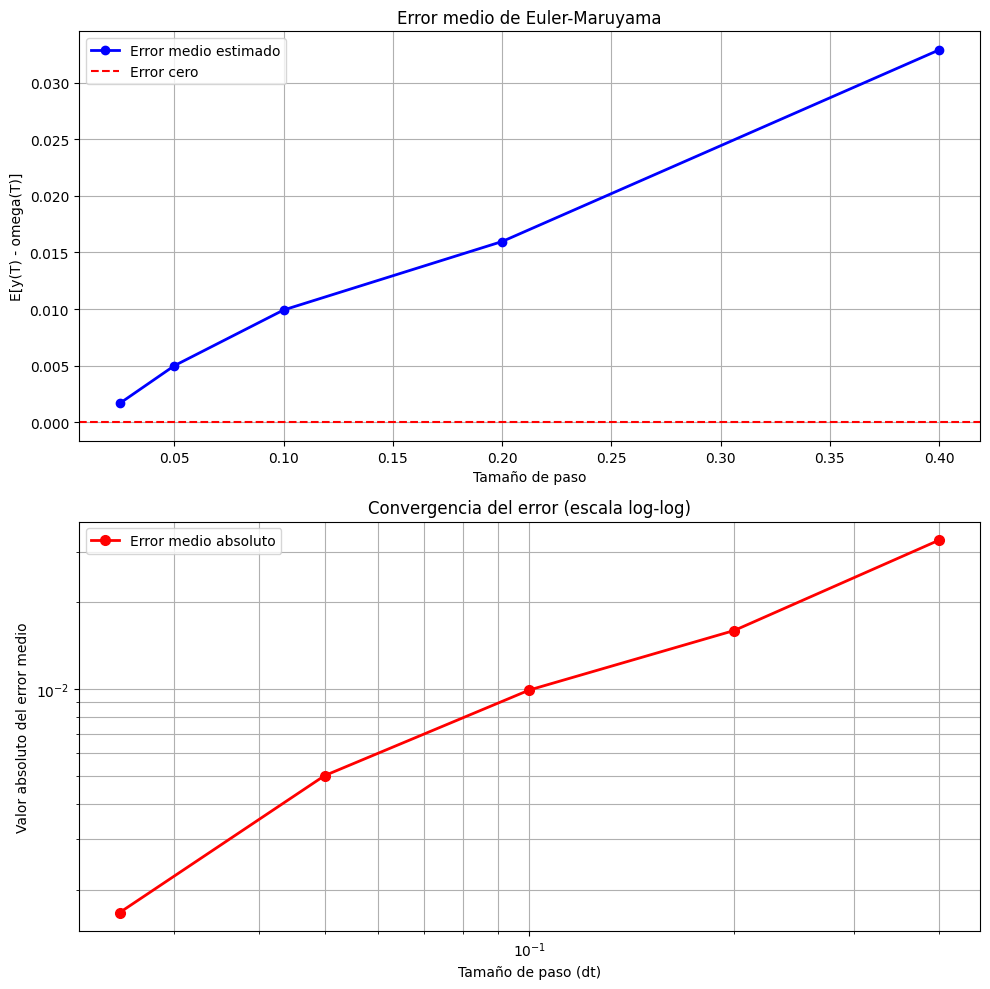

In [3]:


import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETROS
# ==========================================

r = 0.1
sigma = 0.3
y0 = 1
T = 8

N = 10000  # Numero de realizaciones (mayor a 100)

# Diferentes tamanos de paso
pasos = [0.4, 0.2, 0.1, 0.05, 0.025]

np.random.seed(42)

# Almacenar resultados
errores = []
errores_estandar = []

# Guardar resultados para dt = 0.2
resultados = None

# ==========================================
# 2. SIMULACIONES
# ==========================================

for dt in pasos:

    n = int(T / dt)

    # Incrementos del movimiento browniano
    dB = np.random.normal(0, np.sqrt(dt), (N, n))

    # Movimiento browniano acumulado
    B = np.cumsum(dB, axis=1)

    # Solucion aproximada Euler-Maruyama
    W = np.ones(N) * y0

    for i in range(n):
        W = W + r * W * dt + sigma * W * dB[:, i]

    # Solucion exacta en T
    BT = B[:, -1]

    Y_exacta = y0 * np.exp(
        (r - 0.5 * sigma**2) * T + sigma * BT
    )

    # ======================================
    # 3. ERROR SEGUN EL PIZARRON
    # ======================================

    diferencia = Y_exacta - W

    # E[y(T) - omega(T)]
    error_medio = np.mean(diferencia)

    # Error estandar de la estimacion
    error_estandar = np.std(
        diferencia, ddof=1
    ) / np.sqrt(N)

    errores.append(error_medio)
    errores_estandar.append(error_estandar)

    # Guardar datos del paso 0.2
    if dt == 0.2:
        resultados = (Y_exacta, W)

# ==========================================
# 4. MOSTRAR RESULTADOS
# ==========================================

print("ERROR MEDIO - EULER MARUYAMA")
print("Numero de realizaciones:", N)
print("Tiempo final T =", T)
print("----------------------------------------")

print("Paso       Error medio       Error estandar")

for dt, e, ee in zip(
    pasos, errores, errores_estandar
):
    print(f"{dt:6.3f}    {e:12.7f}    {ee:12.7f}")

print("----------------------------------------")

# Resultado para dt = 0.2
indice = pasos.index(0.2)

print("\nRESULTADO PARA dt = 0.2")
print("Error medio:", errores[indice])
print("Error estandar:", errores_estandar[indice])

# ==========================================
# 5. GRAFICAS
# ==========================================

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 10)
)

# Grafica 1: Error medio por realizaciones
ax1.plot(
    pasos,
    errores,
    'bo-',
    linewidth=2,
    label='Error medio estimado'
)

ax1.axhline(
    0,
    color='red',
    linestyle='--',
    label='Error cero'
)

ax1.set_title('Error medio de Euler-Maruyama')
ax1.set_xlabel('Tamaño de paso')
ax1.set_ylabel('E[y(T) - omega(T)]')
ax1.grid(True)
ax1.legend()

# Grafica 2: Grafica log-log
ax2.loglog(
    pasos,
    np.abs(errores),
    'ro-',
    linewidth=2,
    markersize=7,
    label='Error medio absoluto'
)

ax2.set_title('Convergencia del error (escala log-log)')
ax2.set_xlabel('Tamaño de paso (dt)')
ax2.set_ylabel('Valor absoluto del error medio')
ax2.grid(True, which='both')
ax2.legend()

plt.tight_layout()
plt.show()